In [1]:
!pip install -q onnx onnxruntime scikit-learn matplotlib

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import os

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using Device:", device)

PyTorch Version: 2.14.1+cpu
GPU Available: False
Using Device: cpu


In [3]:
class ModelArchitecture(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 2)
        )

    def forward(self, x):
        return self.network(x)


model = ModelArchitecture().to(device)

print("MODEL ARCHITECTURE")
print(model)

MODEL ARCHITECTURE
ModelArchitecture(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=2, bias=True)
  )
)


In [4]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_moons(
    n_samples=2000,
    noise=0.2,
    random_state=42
)

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

X_train = torch.tensor(
    X_train, dtype=torch.float32
).to(device)

X_test = torch.tensor(
    X_test, dtype=torch.float32
).to(device)

y_train = torch.tensor(
    y_train, dtype=torch.long
).to(device)

y_test = torch.tensor(
    y_test, dtype=torch.long
).to(device)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 1600
Testing Samples: 400


In [5]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.01
)

epochs = 100
loss_history = []

for epoch in range(epochs):

    model.train()

    optimizer.zero_grad()

    outputs = model(X_train)

    loss = criterion(outputs, y_train)

    loss.backward()

    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {loss.item():.4f}"
        )

print("\nModel Training Completed!")

Epoch [10/100] Loss: 0.4338
Epoch [20/100] Loss: 0.3066
Epoch [30/100] Loss: 0.2813
Epoch [40/100] Loss: 0.2625
Epoch [50/100] Loss: 0.2441
Epoch [60/100] Loss: 0.2129
Epoch [70/100] Loss: 0.1676
Epoch [80/100] Loss: 0.1187
Epoch [90/100] Loss: 0.0884
Epoch [100/100] Loss: 0.0766

Model Training Completed!


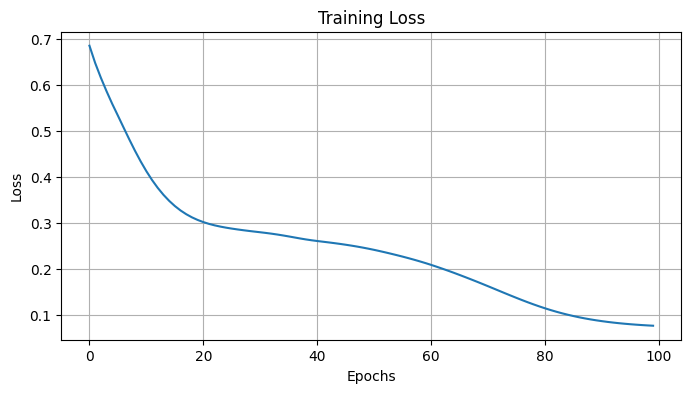

Model Accuracy: 96.74999713897705 %


In [6]:
plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.grid()
plt.show()

model.eval()

with torch.no_grad():

    predictions = model(X_test)

    predicted_classes = torch.argmax(
        predictions, dim=1
    )

    accuracy = (
        predicted_classes == y_test
    ).float().mean()

print("Model Accuracy:", accuracy.item() * 100, "%")

In [7]:
checkpoint = {
    "model_state_dict": model.cpu().state_dict(),
    "input_features": 2,
    "output_classes": 2,
    "epochs": epochs
}

torch.save(
    checkpoint,
    "/content/trained_model.pth"
)

print("Trained Checkpoint Saved Successfully!")
print("File Size:",
      round(os.path.getsize("/content/trained_model.pth") / 1024, 2),
      "KB")

model = model.to(device)

Trained Checkpoint Saved Successfully!
File Size: 3.97 KB


In [8]:
model.eval()

dummy_input = torch.randn(1, 2)

torch.onnx.export(
    model.cpu(),
    dummy_input,
    "/content/model.onnx",
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "output": {0: "batch_size"}
    },
    opset_version=17,
    dynamo=False
)

print("ONNX Model Exported Successfully!")

import onnx

onnx_model = onnx.load("/content/model.onnx")

onnx.checker.check_model(onnx_model)

print("ONNX Graph Validation Successful!")

print(onnx.helper.printable_graph(onnx_model.graph))

model = model.to(device)

/tmp/ipykernel_897/175319189.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX Model Exported Successfully!
ONNX Graph Validation Successful!
graph main_graph (
  %input[FLOAT, batch_sizex2]
) initializers (
  %network.0.weight[FLOAT, 16x2]
  %network.0.bias[FLOAT, 16]
  %network.2.weight[FLOAT, 8x16]
  %network.2.bias[FLOAT, 8]
  %network.4.weight[FLOAT, 2x8]
  %network.4.bias[FLOAT, 2]
) {
  %/network/network.0/Gemm_output_0 = Gemm[alpha = 1, beta = 1, transB = 1](%input, %network.0.weight, %network.0.bias)
  %/network/network.1/Relu_output_0 = Relu(%/network/network.0/Gemm_output_0)
  %/network/network.2/Gemm_output_0 = Gemm[alpha = 1, beta = 1, transB = 1](%/network/network.1/Relu_output_0, %network.2.weight, %network.2.bias)
  %/network/network.3/Relu_output_0 = Relu(%/network/network.2/Gemm_output_0)
  %output = Gemm[alpha = 1, beta = 1, transB = 1](%/network/network.3/Relu_output_0, %network.4.weight, %network.4.bias)
  return %output
}


/tmp/ipykernel_897/175319189.py:29: DeprecationWarning: Deprecated since 1.19. Consider using onnx.printer.to_text() instead.
  print(onnx.helper.printable_graph(onnx_model.graph))


In [9]:
import onnxruntime as ort

session = ort.InferenceSession(
    "/content/model.onnx",
    providers=["CPUExecutionProvider"]
)

sample_input = X_test[:5].cpu().numpy()

onnx_output = session.run(
    ["output"],
    {"input": sample_input}
)

print("ONNX Predictions:")
print(np.argmax(onnx_output[0], axis=1))

ONNX Predictions:
[1 1 0 1 0]


In [10]:
try:
    import tensorrt as trt

    logger = trt.Logger(trt.Logger.WARNING)

    builder = trt.Builder(logger)

    network = builder.create_network(
        1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH)
    )

    parser = trt.OnnxParser(network, logger)

    with open("/content/model.onnx", "rb") as f:
        onnx_data = f.read()

    if not parser.parse(onnx_data):

        print("ONNX Parsing Failed!")

        for i in range(parser.num_errors):
            print(parser.get_error(i))

    else:

        config = builder.create_builder_config()

        config.set_memory_pool_limit(
            trt.MemoryPoolType.WORKSPACE,
            1 << 28
        )

        profile = builder.create_optimization_profile()

        profile.set_shape(
            "input",
            min=(1, 2),
            opt=(32, 2),
            max=(128, 2)
        )

        config.add_optimization_profile(profile)

        engine_data = builder.build_serialized_network(
            network,
            config
        )

        if engine_data is not None:

            with open("/content/model.engine", "wb") as f:
                f.write(engine_data)

            print("TensorRT Engine Created Successfully!")

        else:
            print("TensorRT Engine Creation Failed!")

except ImportError:
    print("TensorRT is not installed. Engine was not generated.")

except Exception as e:
    print("TensorRT Error:", e)

TensorRT is not installed. Engine was not generated.


In [11]:
import os

files_list = [
    "trained_model.pth",
    "model.onnx",
    "model.engine"
]

print("MODEL ARTEFACT LIFECYCLE")
print("=" * 45)

for filename in files_list:

    path = "/content/" + filename

    if os.path.exists(path):

        size = os.path.getsize(path) / 1024

        print(filename, " | ", round(size, 2), "KB")

    else:

        print(filename, " | Not Generated")

MODEL ARTEFACT LIFECYCLE
trained_model.pth  |  3.97 KB
model.onnx  |  1.74 KB
model.engine  | Not Generated


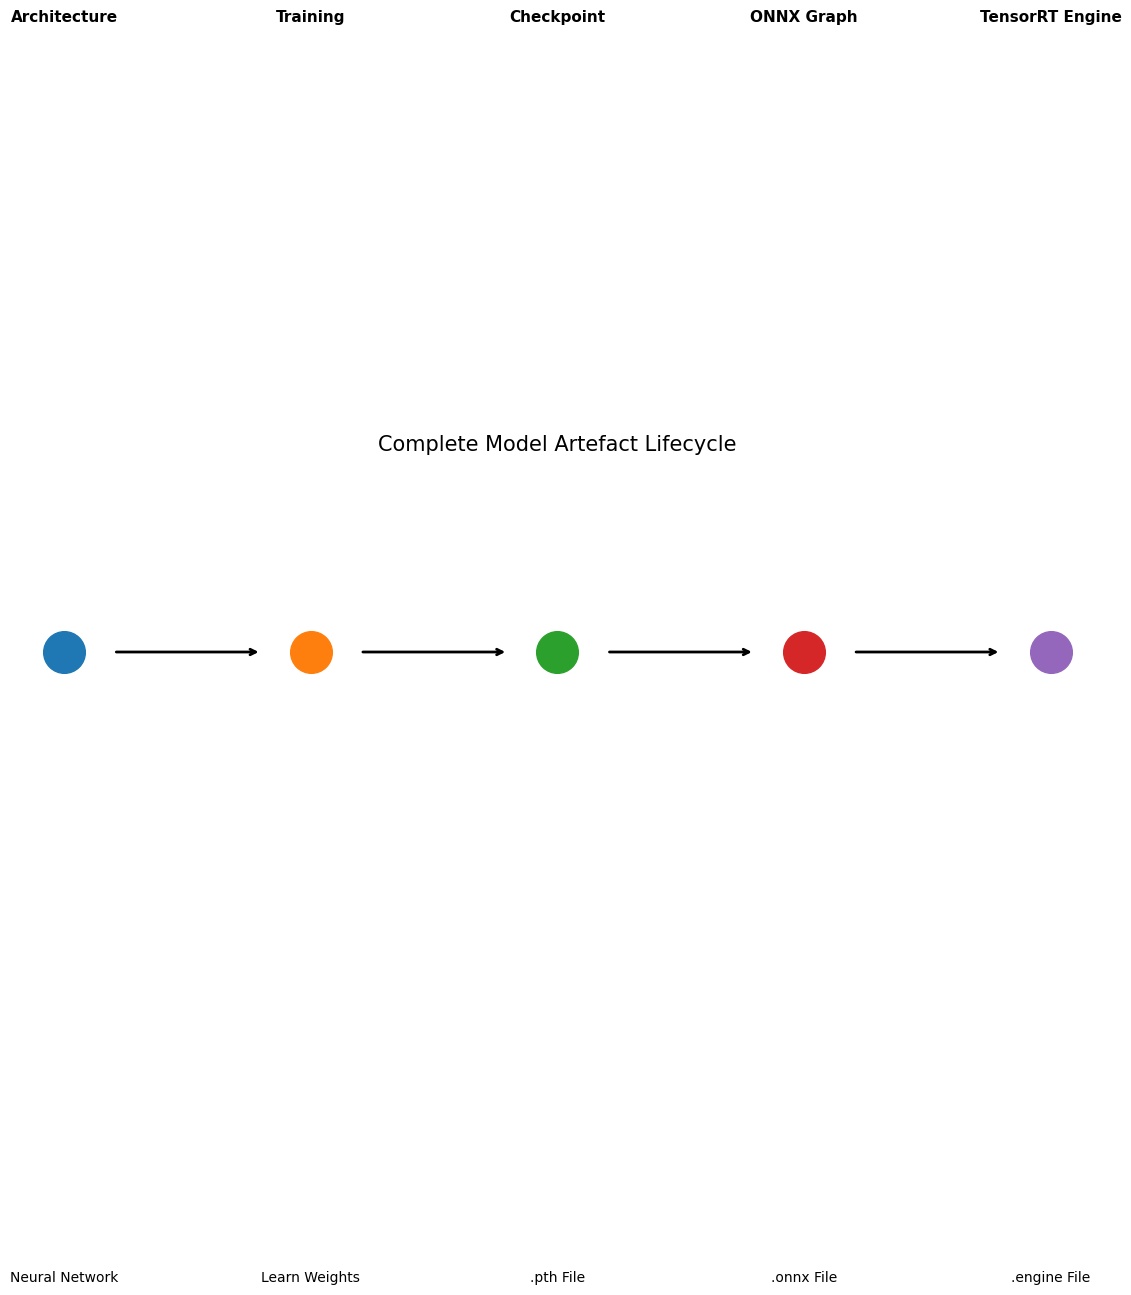

In [12]:
steps = [
    "Architecture",
    "Training",
    "Checkpoint",
    "ONNX Graph",
    "TensorRT Engine"
]

descriptions = [
    "Neural Network",
    "Learn Weights",
    ".pth File",
    ".onnx File",
    ".engine File"
]

plt.figure(figsize=(14, 5))

for i in range(len(steps)):

    plt.scatter(i, 0, s=900)

    plt.text(
        i, 0.18,
        steps[i],
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

    plt.text(
        i, -0.18,
        descriptions[i],
        ha="center",
        fontsize=10
    )

    if i < len(steps) - 1:

        plt.annotate(
            "",
            xy=(i + 0.8, 0),
            xytext=(i + 0.2, 0),
            arrowprops=dict(arrowstyle="->", lw=2)
        )

plt.title(
    "Complete Model Artefact Lifecycle",
    fontsize=15
)

plt.axis("off")
plt.show()

In [13]:
from google.colab import files
import os

download_files = [
    "/content/trained_model.pth",
    "/content/model.onnx",
    "/content/model.engine"
]

for file_path in download_files:

    if os.path.exists(file_path):

        print("Downloading:", os.path.basename(file_path))

        files.download(file_path)

    else:

        print("File not available:", os.path.basename(file_path))

Downloading: trained_model.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: model.onnx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File not available: model.engine
